In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
np.random.seed(42)


/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2015-01.csv
/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-01.csv
/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-02.csv
/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-03.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor

In [3]:
jan16_data = pd.read_csv('/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-01.csv')

In [4]:
jan16_data.head(n=10)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2,2016-01-01 00:00:00,2016-01-01 00:00:00,2,1.10,-73.990372,40.734695,1,N,-73.981842,40.732407,2,7.5,0.5,0.5,0.0,0.0,0.3,8.8
1,2,2016-01-01 00:00:00,2016-01-01 00:00:00,5,4.90,-73.980782,40.729912,1,N,-73.944473,40.716679,1,18.0,0.5,0.5,0.0,0.0,0.3,19.3
2,2,2016-01-01 00:00:00,2016-01-01 00:00:00,1,10.54,-73.984550,40.679565,1,N,-73.950272,40.788925,1,33.0,0.5,0.5,0.0,0.0,0.3,34.3
3,2,2016-01-01 00:00:00,2016-01-01 00:00:00,1,4.75,-73.993469,40.718990,1,N,-73.962242,40.657333,2,16.5,0.0,0.5,0.0,0.0,0.3,17.3
4,2,2016-01-01 00:00:00,2016-01-01 00:00:00,3,1.76,-73.960625,40.781330,1,N,-73.977264,40.758514,2,8.0,0.0,0.5,0.0,0.0,0.3,8.8
5,2,2016-01-01 00:00:00,2016-01-01 00:18:30,2,5.52,-73.980118,40.743050,1,N,-73.913490,40.763142,2,19.0,0.5,0.5,0.0,0.0,0.3,20.3
6,2,2016-01-01 00:00:00,2016-01-01 00:26:45,2,7.45,-73.994057,40.719990,1,N,-73.966362,40.789871,2,26.0,0.5,0.5,0.0,0.0,0.3,27.3
7,1,2016-01-01 00:00:01,2016-01-01 00:11:55,1,1.20,-73.979424,40.744614,1,N,-73.992035,40.753944,2,9.0,0.5,0.5,0.0,0.0,0.3,10.3
8,1,2016-01-01 00:00:02,2016-01-01 00:11:14,1,6.00,-73.947151,40.791046,1,N,-73.920769,40.865578,2,18.0,0.5,0.5,0.0,0.0,0.3,19.3
9,2,2016-01-01 00:00:02,2016-01-01 00:11:08,1,3.21,-73.998344,40.723896,1,N,-73.995850,40.688400,2,11.5,0.5,0.5,0.0,0.0,0.3,12.8


In [5]:
jan16_data['extra'].nunique() # Number of unique values in extra

35

In [6]:
jan16_data['pickup'] = pd.to_datetime(jan16_data['tpep_pickup_datetime'])
jan16_data['dropoff'] = pd.to_datetime(jan16_data['tpep_dropoff_datetime'])
jan16_data['total_duration'] = (jan16_data['dropoff'] - jan16_data['pickup']).dt.total_seconds() / 60

In [7]:
jan16_data = jan16_data.drop(columns=['tpep_pickup_datetime', 'tpep_dropoff_datetime'])

### Analysing the target variable `total_duration`

In [8]:
print(f'Mean of the total Duration distribution: {jan16_data['total_duration'].mean().item():.4f}')
print(f'Stddev of the total Duration distribution: {jan16_data['total_duration'].std():.4f}')
print(f'Maximum duration (in mins): {jan16_data['total_duration'].max()}')
print(f'Minimum duration (in mins): {jan16_data['total_duration'].min()}')
print()
print(jan16_data["total_duration"].describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]))

Mean of the total Duration distribution: 15.2688
Stddev of the total Duration distribution: 86.9071
Maximum duration (in mins): 119912.7
Minimum duration (in mins): -43.95

count    1.090686e+07
mean     1.526881e+01
std      8.690711e+01
min     -4.395000e+01
50%      1.046667e+01
90%      2.551667e+01
95%      3.270000e+01
99%      5.390000e+01
99.9%    1.424050e+03
max      1.199127e+05
Name: total_duration, dtype: float64


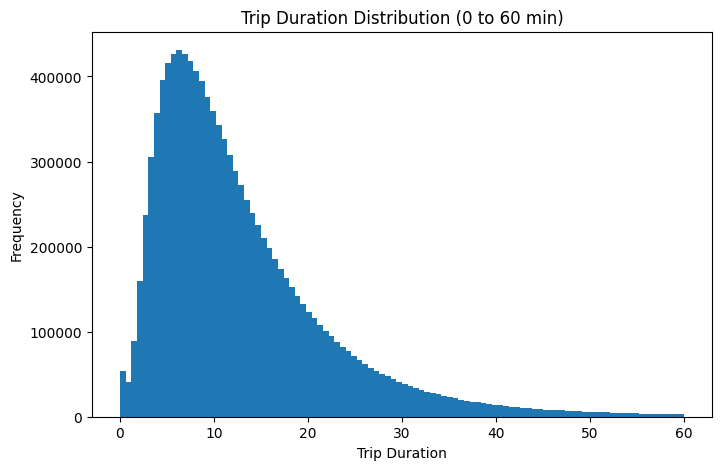

In [9]:
plt.figure(figsize=(8,5))
plt.hist(jan16_data.loc[
    (jan16_data["total_duration"] > 0) & (jan16_data["total_duration"] <= 60),
    "total_duration"
], bins=100)
plt.xlabel("Trip Duration")
plt.ylabel("Frequency")
plt.title("Trip Duration Distribution (0 to 60 min)")
plt.show()

# Looks very right skewed, will have to take care of this!

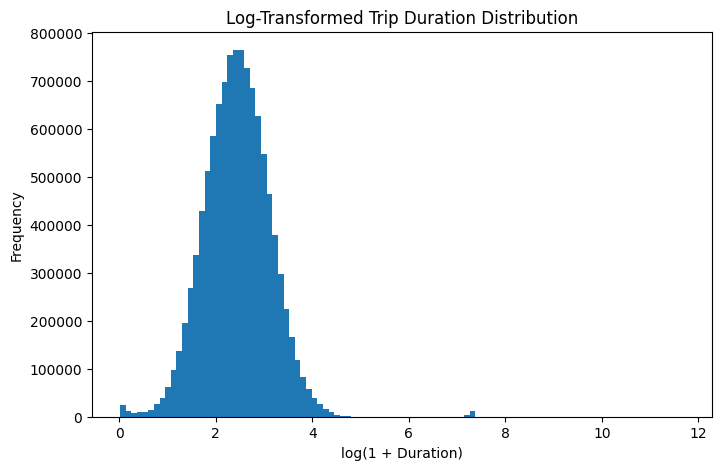

In [10]:
import numpy as np

dur = jan16_data.loc[jan16_data["total_duration"] > 0, "total_duration"]

plt.figure(figsize=(8,5))
plt.hist(np.log1p(dur), bins=100)
plt.xlabel("log(1 + Duration)")
plt.ylabel("Frequency")
plt.title("Log-Transformed Trip Duration Distribution")
plt.show()

# Much better...

In [11]:
# Some very noticeable outliers (such as a trip spanning 83 Days!) - have to remove them
print(jan16_data[jan16_data['total_duration'] <= 0].shape)

(11429, 20)


In [12]:
cleaned_data = jan16_data.copy()
cleaned_data = jan16_data[jan16_data['total_duration'] > 0]

In [13]:
print(len(jan16_data))
print(jan16_data["total_duration"].max())
print(jan16_data["total_duration"].std())

print("="*20)

print(len(cleaned_data))
print(cleaned_data['total_duration'].max())
print(cleaned_data['total_duration'].std())

10906858
119912.7
86.90711256338955
10895429
119912.7
86.95127237551432


### Next - Analysing the Average Speed and removing the outliers

In [14]:
# for t in [60, 120, 180, 360, 720, 1440]:
#     print(t, (cleaned_data["total_duration"] > t).sum())

# Some are valid and some have to be removed
cleaned_data[cleaned_data['total_duration'] > 360][['total_duration', 'trip_distance']].sort_values(by='trip_distance', ascending=False).head(n=15)

,total_duration,trip_distance
1794954,545.866667,485.9
6861871,547.816667,136.4
2110088,494.350000,107.6
5751105,677.650000,102.7
8352038,380.400000,99.3
4492826,427.700000,86.6
8939127,454.800000,81.9
492519,1416.566667,78.4
6023931,393.416667,77.8
8623420,412.966667,76.5


In [15]:
cleaned_data["avg_speed_mph"] = (cleaned_data["trip_distance"] / (cleaned_data["total_duration"] / 60))
print(cleaned_data['avg_speed_mph'].describe(percentiles=[0.9, 0.99, 0.995, 0.999, 0.9995, 0.9999]))

# We will remove the data points where the Average MPH > 100 since that is absurd in NYC traffic

/tmp/ipykernel_49/2013190099.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_data["avg_speed_mph"] = (cleaned_data["trip_distance"] / (cleaned_data["total_duration"] / 60))


count     1.089543e+07
mean      6.250029e+01
std       1.196464e+05
min       0.000000e+00
50%       1.061662e+01
90%       2.008309e+01
99%       3.579310e+01
99.5%     3.960000e+01
99.9%     5.204131e+01
99.95%    4.050000e+02
99.99%    4.860000e+03
max       3.885897e+08
Name: avg_speed_mph, dtype: float64


In [16]:
print(f'Number of Data points to be removed by the speed criteria: {len(cleaned_data[cleaned_data['avg_speed_mph'] > 100])}')

cleaned_data = cleaned_data[cleaned_data['avg_speed_mph'] <= 100]

Number of Data points to be removed by the speed criteria: 8586


### Analysing the trip distance and removing nonsense values

In [17]:
print(cleaned_data['trip_distance'].describe(percentiles=[0.9, 0.99, 0.995, 0.999, 0.9995, 0.9999]))
print('-'*100)
for d in [20, 30, 50, 75, 100, 200]:
    print(d, (cleaned_data["trip_distance"] > d).sum())

count     1.088684e+07
mean      2.898469e+00
std       3.611530e+00
min       0.000000e+00
50%       1.680000e+00
90%       6.500000e+00
99%       1.864000e+01
99.5%     2.011000e+01
99.9%     2.480000e+01
99.95%    2.837000e+01
99.99%    3.900000e+01
max       4.859000e+02
Name: trip_distance, dtype: float64
----------------------------------------------------------------------------------------------------
20 57052
30 3654
50 391
75 70
100 29
200 3


In [18]:
cleaned_data = cleaned_data[(cleaned_data["trip_distance"] > 0) & (cleaned_data["trip_distance"] <= 50)]

## Baseline Model on the Raw and Cleaned data

In [19]:
baseline_raw = jan16_data.sample(n=500000, random_state=42)
features = ["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "passenger_count", "total_duration"]
baseline_raw = baseline_raw[features]
baseline_raw.head(n=5)

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,total_duration
3801703,-73.974640,40.793400,-73.939919,40.794048,1,28.250000
1620092,-73.790215,40.647221,-73.982513,40.762756,1,72.066667
8460962,-73.982170,40.768208,-73.973534,40.760380,1,6.716667
4339863,-73.978729,40.762302,-73.960114,40.781517,1,12.916667
1143050,-73.996086,40.743584,-73.987946,40.762058,1,12.733333


In [20]:
baseline_raw_X = baseline_raw[features[:5]].to_numpy()
baseline_raw_y = baseline_raw[features[-1]].to_numpy().reshape(-1, 1)
baseline_raw_X_train, baseline_raw_X_test, baseline_raw_y_train, baseline_raw_y_test = train_test_split(baseline_raw_X, baseline_raw_y, test_size=0.25, random_state=42)
baseline_raw_model = LinearRegression()
baseline_raw_model.fit(baseline_raw_X_train, baseline_raw_y_train)
baseline_raw_predict = baseline_raw_model.predict(baseline_raw_X_test)
print(f'RMSE Score of the Baseline model on the raw data is: {root_mean_squared_error(baseline_raw_y_test, baseline_raw_predict):.4f}')
print(f"MAE: {mean_absolute_error(baseline_raw_y_test, baseline_raw_predict):.4f}")

RMSE Score of the Baseline model on the raw data is: 57.2100
MAE: 10.2018


In [21]:
baseline_clean = cleaned_data.sample(n=500000, random_state=42)
features = ["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "passenger_count", "total_duration"]
baseline_clean = baseline_clean[features]
baseline_clean.head(n=5)

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,total_duration
7308412,-73.980408,40.742611,-73.948486,40.773823,1,10.016667
6479565,-73.986099,40.762329,-73.983421,40.771309,1,3.216667
6644199,-73.995110,40.760201,-73.985336,40.757240,1,8.550000
7832248,-73.958649,40.760670,-73.969437,40.760452,2,5.650000
4651168,-73.981934,40.745514,-73.974998,40.741680,1,5.100000


In [22]:
baseline_clean_X = baseline_clean[features[:5]].to_numpy()
baseline_clean_y = baseline_clean[features[-1]].to_numpy().reshape(-1, 1)
baseline_clean_X_train, baseline_clean_X_test, baseline_clean_y_train, baseline_clean_y_test = train_test_split(baseline_clean_X, baseline_clean_y, test_size=0.25, random_state=42)
baseline_clean_model = LinearRegression()
baseline_clean_model.fit(baseline_clean_X_train, baseline_clean_y_train)
baseline_clean_predict = baseline_clean_model.predict(baseline_clean_X_test)
print(f'RMSE Score of the Baseline model on the raw data is: {root_mean_squared_error(baseline_clean_y_test, baseline_clean_predict):.4f}')
print(f"MAE: {mean_absolute_error(baseline_clean_y_test, baseline_clean_predict):.4f}")

RMSE Score of the Baseline model on the raw data is: 52.7959
MAE: 9.8636


In [23]:
baseline_clean_model = DecisionTreeRegressor(random_state=42)
baseline_clean_model.fit(baseline_clean_X_train, baseline_clean_y_train)
baseline_clean_predict = baseline_clean_model.predict(baseline_clean_X_test)
baseline_clean_predict_train = baseline_clean_model.predict(baseline_clean_X_train)
print(f'RMSE Score of the Baseline model on the clean data is: {root_mean_squared_error(baseline_clean_y_test, baseline_clean_predict):.4f}')
print(f"MAE: {mean_absolute_error(baseline_clean_y_test, baseline_clean_predict):.4f}")
print('-'*50)
print(f'RMSE Score of the Baseline model on the clean training data is: {root_mean_squared_error(baseline_clean_y_train, baseline_clean_predict_train):.4f}')
print(f"MAE on training data: {mean_absolute_error(baseline_clean_y_train, baseline_clean_predict_train):.4f}")

RMSE Score of the Baseline model on the clean data is: 138.5187
MAE: 9.4284
--------------------------------------------------
RMSE Score of the Baseline model on the clean training data is: 4.8801
MAE on training data: 0.1155


## Dataset specific Feature Engineering

### Feature 1. Derived Distance from pickup and dropoff coordinates

In [24]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 3958.8  # Earth radius in miles

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

cleaned_data["haversine_distance"] = haversine_distance(
    cleaned_data["pickup_latitude"],
    cleaned_data["pickup_longitude"],
    cleaned_data["dropoff_latitude"],
    cleaned_data["dropoff_longitude"]
)

In [25]:
features = ["haversine_distance", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "passenger_count", "total_duration"]
cleaned_df = cleaned_data.sample(n=500000, random_state=42)

main_X = cleaned_df[features[:-1]].to_numpy()
main_y = cleaned_df[features[-1]].to_numpy().reshape(-1, 1)
main_X_train, main_X_test, main_y_train, main_y_test = train_test_split(main_X, main_y, test_size=0.25, random_state=42)
main_linear_model = LinearRegression()
main_linear_model.fit(main_X_train, main_y_train)
main_predict = main_linear_model.predict(main_X_test)
print(f'RMSE score of the Linear Model on Cleaned Data + Distance: {root_mean_squared_error(main_y_test, main_predict):.4f}')
print(f'MAE: {mean_absolute_error(main_y_test, main_predict):.4f}')

RMSE score of the Linear Model on Cleaned Data + Distance: 52.7962
MAE: 9.8614


In [26]:
cleaned_data["haversine_distance"].describe(
    percentiles=[0.5, 0.9, 0.99, 0.999, 0.9999]
)

count     1.083345e+07
mean      1.456582e+01
std       2.589595e+02
min       0.000000e+00
50%       1.263334e+00
90%       4.629608e+00
99%       1.309713e+01
99.9%     5.384858e+03
99.99%    5.385851e+03
max       5.580006e+03
Name: haversine_distance, dtype: float64

In [27]:
cleaned_data[
    ["pickup_latitude", "pickup_longitude",
     "dropoff_latitude", "dropoff_longitude"]
].describe()

,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude
count,1.083345e+07,1.083345e+07,1.083345e+07,1.083345e+07
mean,4.015707e+01,-7.289513e+01,4.022426e+01,-7.301563e+01
std,4.883617e+00,8.864916e+00,4.607383e+00,8.363228e+00
min,0.000000e+00,-1.008229e+02,0.000000e+00,-1.008229e+02
25%,4.073647e+01,-7.399152e+01,4.073500e+01,-7.399109e+01
50%,4.075377e+01,-7.398141e+01,4.075423e+01,-7.397947e+01
75%,4.076812e+01,-7.396623e+01,4.076968e+01,-7.396214e+01
max,6.090876e+01,0.000000e+00,6.090876e+01,0.000000e+00


In [28]:
for t in [60, 120, 180, 240, 360, 720, 1440]:
    print(t, (cleaned_data["total_duration"] > t).sum())

60 73866
120 17561
180 16722
240 16520
360 16287
720 15668
1440 17


In [29]:
print((cleaned_data["pickup_latitude"] == 0).sum())
print((cleaned_data["pickup_longitude"] == 0).sum())
print((cleaned_data["dropoff_latitude"] == 0).sum())
print((cleaned_data["dropoff_longitude"] == 0).sum())

157879
157879
140281
140281


<Axes: >

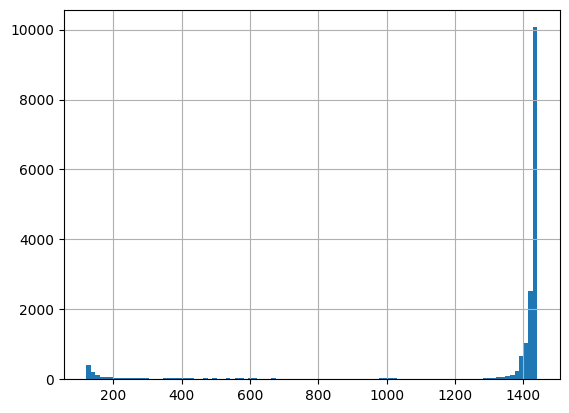

In [30]:
long_trips = cleaned_data[
    cleaned_data["total_duration"].between(120, 1440)
]

long_trips["total_duration"].hist(bins=100)

In [31]:
long_trips["total_duration"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
)

count    17544.000000
mean      1286.880633
std        362.135652
min        120.016667
10%        626.490000
25%       1407.462500
50%       1430.175000
75%       1436.316667
90%       1438.283333
max       1439.966667
Name: total_duration, dtype: float64

In [32]:
suspicious = cleaned_data[
    cleaned_data["total_duration"].between(1400, 1440)
]

suspicious[
    [
        "pickup",
        "dropoff",
        "total_duration",
        "trip_distance"
    ]
].sample(20, random_state=42)

,pickup,dropoff,total_duration,trip_distance
9055638,2016-01-22 18:26:07,2016-01-23 18:23:00,1436.883333,2.00
7147677,2016-01-29 20:09:43,2016-01-30 19:47:33,1417.833333,2.02
3440827,2016-01-16 19:01:10,2016-01-17 18:25:43,1404.550000,3.57
10660559,2016-01-09 21:41:26,2016-01-10 21:25:55,1424.483333,0.48
7678861,2016-01-30 23:55:16,2016-01-31 23:52:13,1436.950000,3.61
10844579,2016-01-10 19:10:33,2016-01-11 19:05:00,1434.450000,10.01
3090549,2016-01-28 17:56:09,2016-01-29 17:55:09,1439.000000,1.83
6763200,2016-01-19 15:16:43,2016-01-20 15:04:13,1427.500000,1.71
2566793,2016-01-15 11:56:54,2016-01-16 11:47:46,1430.866667,1.33
6658208,2016-01-19 10:22:32,2016-01-20 10:14:02,1431.500000,0.81


In [33]:
suspicious = suspicious.copy()
suspicious["minutes_short_of_24h"] = (
    1440 - suspicious["total_duration"]
)

suspicious[
    ["total_duration", "minutes_short_of_24h", "trip_distance"]
].head(20)

,total_duration,minutes_short_of_24h,trip_distance
488,1430.400000,9.600000,3.34
516,1418.433333,21.566667,0.81
1453,1426.050000,13.950000,1.69
1956,1432.983333,7.016667,1.38
2273,1436.816667,3.183333,2.74
2398,1435.800000,4.200000,1.95
2428,1405.366667,34.633333,1.71
3242,1427.483333,12.516667,1.97
3448,1434.000000,6.000000,0.81
4130,1437.066667,2.933333,1.71


### FINAL CLEANING CHECKLIST
- Remove non-positive durations.
- Remove trips with invalid coordinates, using a NYC-area bounding box.
- Remove zero or negative recorded distances.
- Remove impossibly high average speeds (our existing 100 mph threshold).
- Exclude the suspicious near-24-hour durations. Will keep an upper limit of 120 minutes for V1
- Keep the 50-mile distance cutoff we've already investigated.

In [34]:
cleaned_data = jan16_data.copy()
# Starting over for easy cleaning
print(f"{len(cleaned_data)} -> ", end=" ")
cleaned_data = cleaned_data[(cleaned_data['total_duration']>0) & (cleaned_data['total_duration']<=120)]
print(f"{len(cleaned_data)} -> ", end=" ")
cleaned_data = cleaned_data[(cleaned_data['trip_distance']>0) & (cleaned_data['trip_distance']<=50)]
print(f"{len(cleaned_data)} -> ", end=" ")

cleaned_data['avg_speed_mph'] = cleaned_data['trip_distance'] * 60 / cleaned_data['total_duration']
cleaned_data = cleaned_data[(cleaned_data['avg_speed_mph'] > 0) & (cleaned_data['avg_speed_mph'] <= 100)]
print(f"{len(cleaned_data)} -> ", end=" ")
# FOUND COORDS FOR NYC REGION ONLINE AND MADE ROUGH BOUNDING BOX
cleaned_data = cleaned_data[
    cleaned_data["pickup_latitude"].between(40, 42) &
    cleaned_data["dropoff_latitude"].between(40, 42) &
    cleaned_data["pickup_longitude"].between(-75, -72) &
    cleaned_data["dropoff_longitude"].between(-75, -72)
]
print(f"{len(cleaned_data)}")

10906858 ->  10877553 ->  10824404 ->  10815889 ->  10654223


In [35]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 3958.8  # Earth radius in miles

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

cleaned_data["haversine_distance"] = haversine_distance(
    cleaned_data["pickup_latitude"],
    cleaned_data["pickup_longitude"],
    cleaned_data["dropoff_latitude"],
    cleaned_data["dropoff_longitude"]
)

In [36]:
cleaned_data[
    ["haversine_distance", "trip_distance", "total_duration"]
].corr()

,haversine_distance,trip_distance,total_duration
haversine_distance,1.000000,0.969213,0.767616
trip_distance,0.969213,1.000000,0.787995
total_duration,0.767616,0.787995,1.000000


In [37]:
features = ["haversine_distance", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "passenger_count", "total_duration"]
cleaned_df = cleaned_data.sample(n=500000, random_state=42)

main_X = cleaned_df[features[:-1]].to_numpy()
main_y = cleaned_df[features[-1]].to_numpy().reshape(-1, 1)
main_X_train, main_X_test, main_y_train, main_y_test = train_test_split(main_X, main_y, test_size=0.25, random_state=42)
main_linear_model = LinearRegression()
main_linear_model.fit(main_X_train, main_y_train)
main_predict = main_linear_model.predict(main_X_test)
print(f'RMSE score of the Linear Model on Cleaned Data + Distance: {root_mean_squared_error(main_y_test, main_predict):.4f}')
print(f'MAE: {mean_absolute_error(main_y_test, main_predict):.4f}')

RMSE score of the Linear Model on Cleaned Data + Distance: 6.4735
MAE: 4.3766


In [38]:
main_tree_model = DecisionTreeRegressor(max_depth=3, random_state=42)
main_tree_model.fit(main_X_train, main_y_train)
main_tree_predict = main_tree_model.predict(main_X_test)
print(f'RMSE score of the Tree Model on Cleaned Data + Distance: {root_mean_squared_error(main_y_test, main_tree_predict):.4f}')
print(f'MAE: {mean_absolute_error(main_y_test, main_tree_predict):.4f}')

RMSE score of the Tree Model on Cleaned Data + Distance: 6.2860
MAE: 4.1926


In [39]:
features = ["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "passenger_count", "total_duration"]
cleaned_df = cleaned_data.sample(n=500000, random_state=42)

main_X = cleaned_df[features[:-1]].to_numpy()
main_y = cleaned_df[features[-1]].to_numpy().reshape(-1, 1)
main_X_train, main_X_test, main_y_train, main_y_test = train_test_split(main_X, main_y, test_size=0.25, random_state=42)
main_linear_model = LinearRegression()
main_linear_model.fit(main_X_train, main_y_train)
main_predict = main_linear_model.predict(main_X_test)
print(f'RMSE score of the Linear Model on Cleaned Data: {root_mean_squared_error(main_y_test, main_predict):.4f}')
print(f'MAE: {mean_absolute_error(main_y_test, main_predict):.4f}')

RMSE score of the Linear Model on Cleaned Data: 8.9366
MAE: 6.4234


In [40]:
cleaned_data['pickup_day'] = cleaned_data['pickup'].dt.dayofweek

In [41]:
cleaned_data = pd.get_dummies(cleaned_data, columns=['pickup_day'], prefix='day', drop_first=True, dtype=int)

In [42]:
day_features = [f"day_{i}" for i in range(1, 7)]
features = day_features + ["haversine_distance", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "passenger_count", "total_duration"]
cleaned_df = cleaned_data.sample(n=500000, random_state=42)
main_X = cleaned_df[features[:-1]].to_numpy()
main_y = cleaned_df[features[-1]].to_numpy().reshape(-1, 1)
main_X_train, main_X_test, main_y_train, main_y_test = train_test_split(main_X, main_y, test_size=0.25, random_state=42)
main_linear_model = LinearRegression()
main_linear_model.fit(main_X_train, main_y_train)
main_predict = main_linear_model.predict(main_X_test)
print(f'RMSE score of the Linear Model on Cleaned Data + Distance + time: {root_mean_squared_error(main_y_test, main_predict):.4f}')
print(f'MAE: {mean_absolute_error(main_y_test, main_predict):.4f}')

RMSE score of the Linear Model on Cleaned Data + Distance + time: 6.4117
MAE: 4.3291


In [43]:
main_tree_model = DecisionTreeRegressor(max_depth=8, random_state=42)
main_tree_model.fit(main_X_train, main_y_train)
main_tree_predict = main_tree_model.predict(main_X_test)
print(f'RMSE score of the Tree Model on Cleaned Data + Distance + time: {root_mean_squared_error(main_y_test, main_tree_predict):.4f}')
print(f'MAE: {mean_absolute_error(main_y_test, main_tree_predict):.4f}')

RMSE score of the Tree Model on Cleaned Data + Distance + time: 5.9596
MAE: 3.9205


In [44]:
cleaned_data['hour'] = cleaned_data['pickup'].dt.hour
cleaned_data = pd.get_dummies(cleaned_data, columns=['hour'], prefix='hour', drop_first=True, dtype=int)
cleaned_data.columns

Index(['VendorID', 'passenger_count', 'trip_distance', 'pickup_longitude',
       'pickup_latitude', 'RatecodeID', 'store_and_fwd_flag',
       'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount',
       'extra', 'mta_tax', 'tip_amount', 'tolls_amount',
       'improvement_surcharge', 'total_amount', 'pickup', 'dropoff',
       'total_duration', 'avg_speed_mph', 'haversine_distance', 'day_1',
       'day_2', 'day_3', 'day_4', 'day_5', 'day_6', 'hour_1', 'hour_2',
       'hour_3', 'hour_4', 'hour_5', 'hour_6', 'hour_7', 'hour_8', 'hour_9',
       'hour_10', 'hour_11', 'hour_12', 'hour_13', 'hour_14', 'hour_15',
       'hour_16', 'hour_17', 'hour_18', 'hour_19', 'hour_20', 'hour_21',
       'hour_22', 'hour_23'],
      dtype='object')

In [45]:
features = [f'hour_{i}' for i in range(1, 24)] + features
cleaned_df = cleaned_data.sample(n=500000, random_state=42)
main_X = cleaned_df[features[:-1]].to_numpy()
main_y = cleaned_df[features[-1]].to_numpy().reshape(-1, 1)
main_X_train, main_X_test, main_y_train, main_y_test = train_test_split(main_X, main_y, test_size=0.25, random_state=42)
main_linear_model = LinearRegression()
main_linear_model.fit(main_X_train, main_y_train)
main_predict = main_linear_model.predict(main_X_test)
print(f'RMSE score of the Linear Model on Cleaned Data + Time + Hour: {root_mean_squared_error(main_y_test, main_predict):.4f}')
print(f'MAE: {mean_absolute_error(main_y_test, main_predict):.4f}')

RMSE score of the Linear Model on Cleaned Data + Time + Hour: 6.2454
MAE: 4.1859


In [46]:
main_tree_model = DecisionTreeRegressor(max_depth=14, random_state=42)
main_tree_model.fit(main_X_train, main_y_train)
main_tree_predict = main_tree_model.predict(main_X_test)
print(f'RMSE score of the Tree Model on Cleaned Data + Time + Hour: {root_mean_squared_error(main_y_test, main_tree_predict):.4f}')
print(f'MAE: {mean_absolute_error(main_y_test, main_tree_predict):.4f}')

RMSE score of the Tree Model on Cleaned Data + Time + Hour: 5.8489
MAE: 3.7341


In [47]:
from sklearn.ensemble import HistGradientBoostingRegressor
main_grad_model = HistGradientBoostingRegressor(
    max_iter=2000,
    learning_rate=0.05,
    max_leaf_nodes=25,
    random_state=42
)
main_grad_model.fit(main_X_train, main_y_train)
main_grad_predict = main_grad_model.predict(main_X_test)
print(f'RMSE score of the gradboost Model on Cleaned Data + Distance: {root_mean_squared_error(main_y_test, main_grad_predict):.4f}')
print(f'MAE: {mean_absolute_error(main_y_test, main_grad_predict):.4f}')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


RMSE score of the gradboost Model on Cleaned Data + Distance: 4.9329
MAE: 3.1527


In [48]:
main_grad_model.n_iter_

1136

In [49]:
main_grad_train_pred = main_grad_model.predict(main_X_train)
root_mean_squared_error(main_y_train, main_grad_train_pred)

4.737794236154318

## Evaluation with a validation set

In [51]:
# Same 500k sample, but 60/20/20 this time so all the tuning happens on validation and test is only used at the end
eval_X_train, eval_X_test, eval_y_train, eval_y_test = train_test_split(main_X, main_y.ravel(), test_size=0.2, random_state=42)
eval_X_train, eval_X_val, eval_y_train, eval_y_val = train_test_split(eval_X_train, eval_y_train, test_size=0.25, random_state=42)
print(eval_X_train.shape, eval_X_val.shape, eval_X_test.shape)

(300000, 35) (100000, 35) (100000, 35)


In [52]:
# Linear Regression has nothing to tune, so it just gets a validation and a test score
eval_linear_model = LinearRegression()
eval_linear_model.fit(eval_X_train, eval_y_train)
eval_linear_val = eval_linear_model.predict(eval_X_val)
eval_linear_predict = eval_linear_model.predict(eval_X_test)
print(f'Validation RMSE of the Linear Model: {root_mean_squared_error(eval_y_val, eval_linear_val):.4f}')
print(f'MAE: {mean_absolute_error(eval_y_val, eval_linear_val):.4f}')
print(f'Test RMSE of the Linear Model: {root_mean_squared_error(eval_y_test, eval_linear_predict):.4f}')
print(f'MAE: {mean_absolute_error(eval_y_test, eval_linear_predict):.4f}')

Validation RMSE of the Linear Model: 6.2540
MAE: 4.1958
Test RMSE of the Linear Model: 6.2253
MAE: 4.1783


In [53]:
# Picking the tree depth on validation this time instead of trying depths against the test set
val_rmse = {}
for depth in [6, 8, 10, 12, 14, 16, 18, 20]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(eval_X_train, eval_y_train)
    val_rmse[depth] = root_mean_squared_error(eval_y_val, tree.predict(eval_X_val))
    print(depth, round(val_rmse[depth], 4))
best_depth = min(val_rmse, key=val_rmse.get)
print(f'Best depth on validation: {best_depth}')

6 6.0265
8 5.9354
10 5.8552
12 5.8565
14 5.8824
16 5.9478
18 6.1629
20 6.3092
Best depth on validation: 10


In [54]:
# Retraining with the depth validation picked, and scoring it on test only once
eval_tree_model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
eval_tree_model.fit(eval_X_train, eval_y_train)
eval_tree_val = eval_tree_model.predict(eval_X_val)
eval_tree_predict = eval_tree_model.predict(eval_X_test)
print(f'Validation RMSE of the Tree Model (max_depth={best_depth}): {root_mean_squared_error(eval_y_val, eval_tree_val):.4f}')
print(f'MAE: {mean_absolute_error(eval_y_val, eval_tree_val):.4f}')
print(f'Test RMSE of the Tree Model (max_depth={best_depth}): {root_mean_squared_error(eval_y_test, eval_tree_predict):.4f}')
print(f'MAE: {mean_absolute_error(eval_y_test, eval_tree_predict):.4f}')

Validation RMSE of the Tree Model (max_depth=10): 5.8552
MAE: 3.8232
Test RMSE of the Tree Model (max_depth=10): 5.8109
MAE: 3.8001


In [56]:
# Early stopping now watches our own validation set instead of a random slice of the training data
eval_grad_model = HistGradientBoostingRegressor(
    max_iter=2000,
    learning_rate=0.05,
    max_leaf_nodes=25,
    early_stopping=False,
    random_state=42
)
eval_grad_model.fit(eval_X_train, eval_y_train)
best_iter, best_val_rmse = 0, float('inf')
for i, val_pred in enumerate(eval_grad_model.staged_predict(eval_X_val)):
    if root_mean_squared_error(eval_y_val, val_pred) < best_val_rmse:
        best_iter, best_val_rmse, eval_grad_val = i + 1, root_mean_squared_error(eval_y_val, val_pred), val_pred
for i, test_pred in enumerate(eval_grad_model.staged_predict(eval_X_test)):
    if i + 1 == best_iter:
        eval_grad_predict = test_pred
        break
print(f'Validation RMSE of the gradboost Model: {root_mean_squared_error(eval_y_val, eval_grad_val):.4f}')
print(f'MAE: {mean_absolute_error(eval_y_val, eval_grad_val):.4f}')
print(f'Test RMSE of the gradboost Model: {root_mean_squared_error(eval_y_test, eval_grad_predict):.4f}')
print(f'MAE: {mean_absolute_error(eval_y_test, eval_grad_predict):.4f}')
print(f'Best round on validation: {best_iter}')

Validation RMSE of the gradboost Model: 4.8758
MAE: 3.0988
Test RMSE of the gradboost Model: 4.8627
MAE: 3.0903
Best round on validation: 2000
